# Previsão de Cancelamento de Reservas de Hotel

## Contexto do problema

Este projeto utiliza o dataset Hotel Booking Demand, disponível no Kaggle,
com 119.390 reservas e 32 colunas.

O objetivo é treinar uma rede neural MLP para prever se uma reserva será
cancelada, utilizando informações sobre antecedência, duração da estadia,
quantidade de adultos, tipo de hotel e segmento de mercado.

Essa previsão pode auxiliar o hotel no planejamento da ocupação e na
identificação de reservas com maior risco de cancelamento.

Fonte: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

## Dicionário de dados

Foram selecionadas seis variáveis de entrada e uma variável alvo.

| Coluna | Tipo | Significado |
|---|---|---|
| lead_time | Inteiro | Dias entre a realização da reserva e a chegada prevista |
| stays_in_weekend_nights | Inteiro | Quantidade de noites reservadas de sábado ou domingo |
| stays_in_week_nights | Inteiro | Quantidade de noites reservadas de segunda a sexta-feira |
| adults | Inteiro | Quantidade de adultos |
| hotel | Texto | Tipo de hotel: City Hotel ou Resort Hotel |
| market_segment | Texto | Segmento de mercado da reserva, como Direct, Corporate ou Online TA |
| is_canceled | Inteiro | Variável alvo: 0 indica não cancelada e 1 indica cancelada |

As seis entradas selecionadas não possuem valores ausentes.
As demais colunas serão mantidas no CSV original, mas não serão utilizadas
como entradas do modelo.

In [17]:
import sys
import pandas as pd
import sklearn

print("Python do projeto:", sys.executable)
print("Ambiente pronto!")

Python do projeto: /Users/anandamazine/Documents/am-at2-redes-neurais/.venv/bin/python
Ambiente pronto!


In [18]:
from pathlib import Path

# Localiza o CSV, Lê o CSV, guarda a tabela na variável df e mostra as 5 primeiras linhas da tabela
caminho = Path("../data/dataset.csv")

if not caminho.exists():
    caminho = Path("../data/dataset.csv")
df = pd.read_csv(caminho)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [19]:
print("Quantidade de reservas:", df.shape[0])
print("Quantidade de coliunas:", df.shape[1])

print("\nNomes das colunas:")
print(df.columns.tolist())

Quantidade de reservas: 119390
Quantidade de coliunas: 32

Nomes das colunas:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


In [20]:
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [21]:
# Quantidade de valores nulos/ausentes por coluna
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [22]:
#resumo sobre a tabela
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

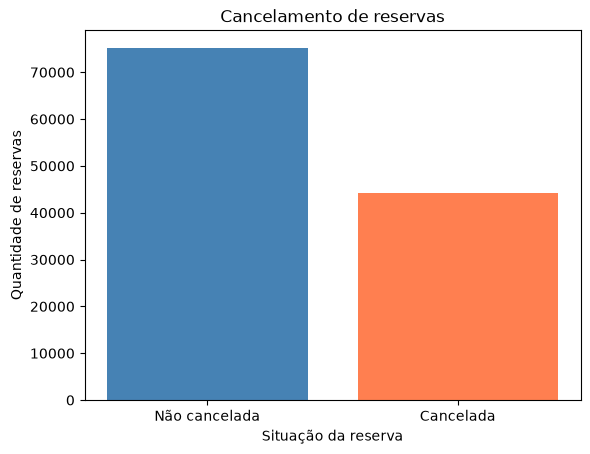

In [24]:
import matplotlib.pyplot as plt

contagem = df["is_canceled"].value_counts().sort_index()

plt.bar(
    ["Não cancelada", "Cancelada"],
    contagem.values,
    color=["steelblue", "coral"]
)

plt.title("Cancelamento de reservas")
plt.xlabel("Situação da reserva")
plt.ylabel("Quantidade de reservas")
plt.show()

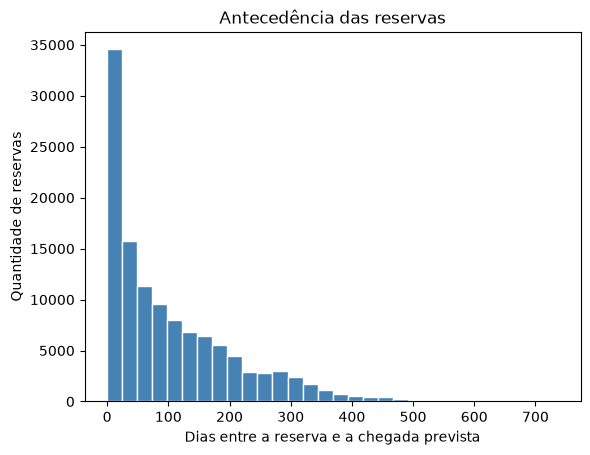

In [27]:
plt.hist(
    df["lead_time"],
    bins=30,
    color="steelblue",
    edgecolor="white"
)
plt.title("Antecedência das reservas")
plt.xlabel("Dias entre a reserva e a chegada prevista")
plt.ylabel("Quantidade de reservas")
plt.show()

In [23]:
# Entradas numéricas
colunas_num = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
]

# Entradas categóricas
colunas_cat = [
    "hotel",
    "market_segment",
]

# Tabela com as entradas esolhidas
X = df[colunas_num + colunas_cat]

# Resposta previsão
y = df["is_canceled"]

display(X.head())

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,hotel,market_segment
0,342,0,0,2,Resort Hotel,Direct
1,737,0,0,2,Resort Hotel,Direct
2,7,0,1,1,Resort Hotel,Direct
3,13,0,1,1,Resort Hotel,Corporate
4,14,0,2,2,Resort Hotel,Online TA
